<a href="https://colab.research.google.com/github/annaring2023/names_2027/blob/main/part_C_poland_forecast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part C: Poland, Ukraine, and the data for the 2027 forecast

What this notebook does:
1. Loads the Polish baby names and puts them in the same table format as the US data.
2. Compares how concentrated names are in the USA and in Poland.
3. Checks that we have every variable we need to forecast the 2027 top-10 with a logit model,
   and runs a first test of that model.
4. Explains why we do not use Ukrainian data.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Data:
- **USA**: SSA baby names 1880–2025, https://www.ssa.gov/oact/babynames/limits.html
  (same `names.zip` as in parts A and B; names given to fewer than 5 babies are not published).
- **Poland**: baby names from the Polish population register (PESEL), 2000–2025,
  https://dane.gov.pl/pl/dataset/219,imiona-nadawane-dzieciom-w-polsce
  (names given to only 1 baby are not published).

### How to get the Polish files
On the dataset page, download (CSV or XLSX) only the files with **"imię pierwsze"** (first name)
for **whole years**:
- *Imiona nadane dzieciom w Polsce w latach 2000-2019 – imię pierwsze* (one file for 20 years);
- for every year 2020–2025: *Imiona męskie …* (boys) and *Imiona żeńskie …* (girls) *… w YYYY r. – imię pierwsze*.

Do not take the half-year files (*w I połowie*) or the second-name files (*imię drugie*).
Put all files into the folder `poland` in your Google Drive (My Drive). If a file name has no
year (the 2025 files are called just *imiona_meskie_nadane_dzieciom_w_Polsce.csv* and
*imiona_zenskie_…*), add the year to its name, e.g. `imiona_meskie_2025.csv`. The code finds the
columns, the sex and the year by itself and skips half-year files if you took one by mistake.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
%pip install -q numpy pandas scipy matplotlib statsmodels openpyxl

In [ ]:
import re, zipfile, unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

POLAND_DIR = "/content/drive/MyDrive/poland"
COLORS = {"F": "#C44E52", "M": "#4C72B0"}
LABELS = {"F": "Girls", "M": "Boys"}

### If dane.gov.pl does not open in your browser: download the files from Colab
This cell asks the dane.gov.pl API for the list of all files in the dataset, keeps only the
whole-year "imię pierwsze" files and saves them into `POLAND_DIR`. Run it once; if the folder already
has files, it does nothing.

In [ ]:
import requests

def download_poland(folder=POLAND_DIR):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    if any(folder.iterdir()):
        print("folder is not empty, nothing to download"); return

    # list of all files in the dataset, with their download links
    meta = requests.get("https://api.dane.gov.pl/1.4/datasets/219/resources/metadata.csv?lang=en",
                        timeout=60).text
    links = sorted(set(re.findall(r"https://api\.dane\.gov\.pl/resources/\d+,[a-z0-9-]+/file", meta)))
    keep = [u for u in links
            if "imie-pierwsze" in u and "polowie" not in u and "wojewodztw" not in u]
    print(f"{len(links)} files in the dataset, {len(keep)} whole-year first-name files")

    for url in keep:
        r = requests.get(url, timeout=120)
        r.raise_for_status()
        ext = ".xlsx" if r.content[:2] == b"PK" else ".csv"      # xlsx files start with 'PK'
        name = url.split("/")[-2].split(",", 1)[1] + ext
        (folder / name).write_bytes(r.content)
        print("saved", name)

download_poland()

folder is not empty, nothing to download


## 1. Load the US data (the same code as in parts A and B)

In [ ]:
def load_names(zip_path="/content/drive/MyDrive/names.zip", data_dir="data/names"):
    data_dir = Path(data_dir)
    if not any(data_dir.glob("yob*.txt")):
        data_dir.mkdir(parents=True, exist_ok=True)
        zipfile.ZipFile(zip_path).extractall(data_dir)

    frames = []
    for path in sorted(data_dir.glob("yob*.txt")):
        df = pd.read_csv(path, header=None, names=["name", "sex", "count"])
        df["year"] = int(path.stem[3:])
        frames.append(df)
    names = pd.concat(frames, ignore_index=True)
    return add_rank_share(names)

def add_rank_share(names):
    names = names.copy()
    names["rank"] = (names.groupby(["year", "sex"])["count"].rank(method="first", ascending=False).astype(int))
    names["share"] = names["count"] / names.groupby(["year", "sex"])["count"].transform("sum")
    return names.sort_values(["year", "sex", "rank"]).reset_index(drop=True)

names = load_names()
print(f"USA: {len(names):,} rows, years {names.year.min()}–{names.year.max()}")

USA: 2,181,032 rows, years 1880–2025


## 2. Load the Polish data and make it look like the US data

The Polish files are different from the US files:
- the columns have Polish names, e.g. `IMIĘ_PIERWSZE` (first name), `PŁEĆ` (sex),
  `LICZBA_WYSTĄPIEŃ` (count), or `Rok` (year), `Imię`, `Liczba`, `Płeć` in the 2000–2019 file;
- sex is written as `K` (*kobieta*, woman) or `M` (*mężczyzna*, man);
- names are written in capital letters (`ZOFIA`).

We turn every file into the US format: `name, sex (F/M), count, year`, and then add `rank` and
`share` with the same function as for the USA.

In [ ]:
def plain(text):
    # remove Polish letters so that column names are easy to match: 'PŁEĆ' -> 'PLEC'
    text = str(text).replace("ł", "l").replace("Ł", "L")
    text = unicodedata.normalize("NFKD", text)
    return "".join(c for c in text if not unicodedata.combining(c)).upper().strip()

def read_table(path):
    if path.suffix.lower() in (".xlsx", ".xls"):
        return pd.read_excel(path)
    for encoding in ("utf-8-sig", "cp1250"):       # cp1250 = old Polish Windows encoding
        try:
            return pd.read_csv(path, sep=None, engine="python", encoding=encoding)
        except UnicodeDecodeError:
            pass
    raise ValueError(f"cannot read {path.name}")

def find_column(columns, word):
    for c in columns:
        if word in plain(c):
            return c
    return None

def read_poland_file(path):
    path = Path(path)
    file_name = plain(path.name)
    if "POLOW" in file_name or "DRUGIE" in file_name:   # half-year or second-name file
        print("skipped:", path.name)
        return None

    df = read_table(path)
    col_name, col_count = find_column(df.columns, "IMI"), find_column(df.columns, "LICZBA")
    col_sex, col_year = find_column(df.columns, "PLEC"), find_column(df.columns, "ROK")
    if col_name is None or col_count is None:
        raise ValueError(f"{path.name}: no name or count column, columns are {list(df.columns)}")

    out = pd.DataFrame({
        "name": df[col_name].astype(str).str.strip().str.title(),     # 'ZOFIA' -> 'Zofia'
        "count": pd.to_numeric(df[col_count], errors="coerce"),
    })

    # sex: from the column, or from the file name (zenskie = girls, meskie = boys)
    if col_sex is not None:
        out["sex"] = df[col_sex].map(lambda v: plain(v)[:1]).map({"K": "F", "M": "M"})
    elif "ZENSK" in file_name:
        out["sex"] = "F"
    elif "MESK" in file_name:
        out["sex"] = "M"
    else:
        raise ValueError(f"{path.name}: cannot find the sex")

    # year: from the column, or from the file name
    if col_year is not None:
        out["year"] = pd.to_numeric(df[col_year], errors="coerce")
    else:
        years = re.findall(r"(?:19|20)\d\d", path.name)
        if len(years) != 1:
            raise ValueError(f"{path.name}: no year in the file name. "
                             f"Rename the file and add the year, e.g. ..._2025.csv")
        out["year"] = int(years[0])
    return out.dropna()

def load_poland(folder=POLAND_DIR):
    files = sorted(p for p in Path(folder).iterdir() if p.suffix.lower() in (".csv", ".xlsx", ".xls"))
    tables = [t for t in (read_poland_file(p) for p in files) if t is not None]
    pl = pd.concat(tables, ignore_index=True)
    pl[["count", "year"]] = pl[["count", "year"]].astype(int)
    # if the same name and year appear in two files, keep it once
    pl = pl.groupby(["year", "sex", "name"], as_index=False)["count"].max()
    return add_rank_share(pl)[["name", "sex", "count", "year", "rank", "share"]]

poland = load_poland()
Path("data").mkdir(exist_ok=True)
poland.to_csv("data/poland_names.csv", index=False)     # data/ is in .gitignore
print(f"Poland: {len(poland):,} rows, years {poland.year.min()}–{poland.year.max()}")
poland[poland.year == poland.year.max()].groupby("sex").head(5)

Poland: 34,799 rows, years 2000–2025


,name,sex,count,year,rank,share
32895,Zofia,F,4415,2025,1,0.036857
32896,Zuzanna,F,3881,2025,2,0.032399
32897,Maja,F,3873,2025,3,0.032332
32898,Laura,F,3821,2025,4,0.031898
32899,Hanna,F,3452,2025,5,0.028818
33834,Nikodem,M,5772,2025,1,0.045663
33835,Antoni,M,5253,2025,2,0.041557
33836,Leon,M,5079,2025,3,0.040181
33837,Jan,M,5054,2025,4,0.039983
33838,Aleksander,M,4687,2025,5,0.037080


### Check: is every year there?

In [ ]:
coverage = (poland.groupby(["year", "sex"])
                  .agg(names=("name", "size"), babies=("count", "sum"), smallest_count=("count", "min"))
                  .unstack("sex"))
for sex in ["F", "M"]:
    have = set(poland.loc[poland.sex == sex, "year"])
    missing = sorted(set(range(2000, 2026)) - have)
    print(f"{LABELS[sex]}: missing years:", missing or "none")
coverage

Girls: missing years: [2020]
Boys: missing years: none


names            babies           smallest_count     
sex        F       M         F         M              F    M
year                                                        
2000   414.0   382.0  187142.0  197263.0            5.0  5.0
2001   398.0   403.0  181975.0  191947.0            5.0  5.0
2002   391.0   401.0  175590.0  185415.0            5.0  5.0
2003   415.0   403.0  173995.0  183215.0            5.0  5.0
2004   435.0   417.0  176779.0  186903.0            5.0  5.0
2005   436.0   424.0  183112.0  192820.0            5.0  5.0
2006   456.0   445.0  190437.0  200796.0            5.0  5.0
2007   495.0   460.0  201448.0  211946.0            5.0  5.0
2008   515.0   484.0  216632.0  227408.0            5.0  5.0
2009   511.0   484.0  219811.0  230881.0            5.0  5.0
2010   515.0   487.0  216566.0  229289.0            5.0  5.0
2011   506.0   468.0  204174.0  216221.0            5.0  5.0
2012   495.0   485.0  203908.0  216021.0            5.0  5.0
2013   993.0   995.0  196714.0  207514.0            2.0  2.0
2014   999.0  1006.0  199953.0  211319.0            2.0  2.0
2015  1003.0  1013.0  199267.0  210571.0            2.0  2.0
2016   937.0   938.0  203546.0  214638.0            2.0  2.0
2017   863.0   812.0  209145.0  220634.0            2.0  2.0
2018   752.0   790.0  194769.0  206849.0            2.0  2.0
2019   823.0   812.0  188557.0  199134.0            2.0  2.0
2020     NaN   799.0       NaN  186590.0            NaN  2.0
2021   822.0   860.0  165856.0  175132.0            2.0  2.0
2022  1015.0  1033.0  155704.0  163864.0            2.0  2.0
2023   976.0   984.0  138666.0  145349.0            2.0  2.0
2024   978.0   967.0  126456.0  134314.0            2.0  2.0
2025   939.0   965.0  119788.0  126404.0            2.0  2.0

What we expect: all years 2000–2025 for girls and boys, and `babies` a bit below the number of
births in Poland (about 250–420 thousand a year), because rare names are hidden. Note: in the
2000–2019 file the smallest count is **5 for 2000–2012** and **2 for 2013–2019**, so the cut-off
changes inside the Polish data too. This is one more reason to use the same 5-baby cut-off everywhere.

## 3. USA vs Poland

The two datasets cut off rare names at different places: the USA hides names with fewer than
**5** babies, Poland only names with **1** baby. So before we compare, we also remove Polish
names with fewer than 5 babies.

We compare only the **top-10 share** (the % of babies who got one of the 10 most popular names).
As part B explains, this measure is almost not affected by the cut-off. Entropy and the number of
distinct names depend on the cut-off and on how many babies are born (the USA has about 13 times
more births), so we do not compare them between countries.

Polish rows removed by the 5-baby cut-off: 10,642 of 34,799


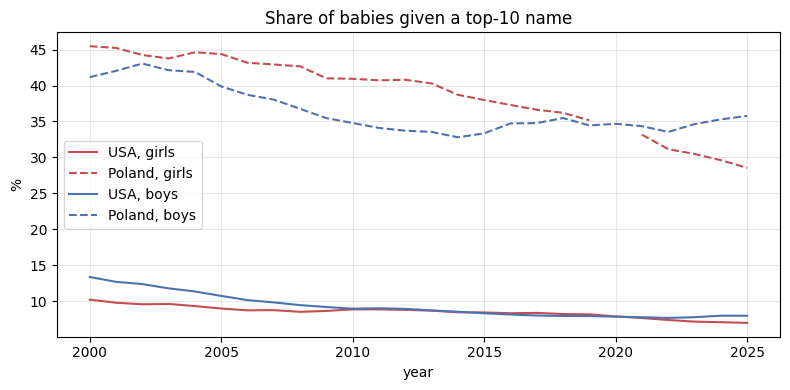

USA       Poland      
sex      F     M      F     M
year                         
2000  10.2  13.4   45.5  41.2
2010   8.9   9.0   40.9  34.8
2025   7.0   8.0   28.6  35.8

In [ ]:
poland5 = add_rank_share(poland[poland["count"] >= 5][["name", "sex", "count", "year"]])
print(f"Polish rows removed by the 5-baby cut-off: {len(poland) - len(poland5):,} of {len(poland):,}")

def top10_share(df):
    return 100 * df[df["rank"] <= 10].groupby(["year", "sex"])["share"].sum().unstack("sex")

top_us, top_pl = top10_share(names), top10_share(poland5)
last_year = min(top_us.index.max(), top_pl.index.max())

fig, ax = plt.subplots(figsize=(8, 4))
for sex in ["F", "M"]:
    ax.plot(top_us.loc[2000:, sex], color=COLORS[sex], label=f"USA, {LABELS[sex].lower()}")
    ax.plot(top_pl[sex], color=COLORS[sex], ls="--", label=f"Poland, {LABELS[sex].lower()}")
ax.set_xlabel("year"); ax.set_ylabel("%")
ax.set_title("Share of babies given a top-10 name")
ax.grid(alpha=0.3); ax.legend(); plt.tight_layout(); plt.show()

pd.concat({"USA": top_us, "Poland": top_pl}, axis=1).loc[[2000, 2010, last_year]].round(1)

**Reading.** In Poland names are much more concentrated than in the USA: in 2025 the top-10
names covered 28.6% of girls and 35.8% of boys, against 7.0% and 8.0% in the USA (about 4 times
more). For girls the share is falling in Poland too (45.5% in 2000, 40.9% in 2010, 28.6% in 2025).
For boys it fell from 41.2% in 2000 to 34.8% in 2010 and then stopped (35.8% in 2025), which is
similar to what part B found for US boys after about 2018.

## 4. Do we have all variables for the 2027 forecast?

**The question.** Which names will be in the top-10 in 2027? Our last data year is 2025, so 2027 is
**two years ahead**.

**The model (logit).** For every year $t$ and sex we take the 30 most popular names. These are the
candidates: in our data a name almost never jumps into the top-10 from further down. For each
candidate the answer is yes or no:

$$y = 1 \text{ if the name is in the top-10 two years later (in year } t+2), \text{ otherwise } y = 0.$$

A logit model gives the probability of $y = 1$ from things we already know in year $t$:

| variable | what it means | why it may help |
|---|---|---|
| `log_share` | log of the name's share in year $t$ | more popular names are more likely to be in the top-10 |
| `growth` | change of `log_share` from $t-1$ to $t$ | rising names go up, falling names go down |
| `in_top10` | 1 if the name is already in the top-10 in year $t$ | part B: about 9 of 10 names stay |
| `years_in_top10` | how many years in a row the name has been in the top-10 (up to 10) | part B: names that stayed longer leave less often |
| `girl` | 1 for girls, 0 for boys | girls' top-10 changes a bit more often (part B) |

The code builds this table and shows for every variable the first and last year where it exists
and how many values are missing. $y$ exists only up to $t = 2023$, because we need $t + 2 \le 2025$.

In [ ]:
FEATURES = ["log_share", "growth", "in_top10", "years_in_top10", "girl"]

def build_table(df, ahead=2, candidates=30):
    df = df[["name", "sex", "year", "rank", "share"]]
    # keep only names that were among the candidates at least once (makes the tables small)
    ever = df.loc[df["rank"] <= candidates, ["name", "sex"]].drop_duplicates()
    df = df.merge(ever, on=["name", "sex"])
    rank = df.pivot_table(index=["name", "sex"], columns="year", values="rank")
    share = df.pivot_table(index=["name", "sex"], columns="year", values="share")
    in_top = (rank <= 10).astype(int)       # missing name = not in the top-10

    rows = []
    for t in rank.columns:
        cand = rank.index[rank[t] <= candidates]
        # years in a row in the top-10, counting back from year t (at most 10)
        streak = pd.Series(0, index=cand)
        still = pd.Series(True, index=cand)
        for k in range(10):
            if t - k not in in_top.columns:
                break
            still &= in_top.loc[cand, t - k].astype(bool)
            streak += still.astype(int)
        rows.append(pd.DataFrame({
            "year": t,
            "rank": rank.loc[cand, t],
            "log_share": np.log(share.loc[cand, t]),
            "growth": (np.log(share.loc[cand, t]) - np.log(share.loc[cand, t - 1])
                       if t - 1 in share.columns else np.nan),
            "in_top10": in_top.loc[cand, t],
            "years_in_top10": streak,
            "y": in_top.loc[cand, t + ahead] if t + ahead in in_top.columns else np.nan,
        }, index=cand))
    table = pd.concat(rows).reset_index()
    table["girl"] = (table["sex"] == "F").astype(int)
    return table

def variable_check(table):
    report = []
    for v in FEATURES + ["y"]:
        ok = table.dropna(subset=[v])
        report.append({"variable": v, "first year": ok.year.min(), "last year": ok.year.max(),
                       "missing, %": round(100 * table[v].isna().mean(), 1)})
    return pd.DataFrame(report)

table_us = build_table(names)
print(f"USA: {len(table_us):,} rows (name x year)")
variable_check(table_us)

USA: 8,760 rows (name x year)


,variable,first year,last year,"missing, %"
0,log_share,1880,2025,0.0
1,growth,1881,2025,0.7
2,in_top10,1880,2025,0.0
3,years_in_top10,1880,2025,0.0
4,girl,1880,2025,0.0
5,y,1880,2023,1.4


In [ ]:
table_pl = build_table(poland5)
print(f"Poland: {len(table_pl):,} rows (name x year)")
variable_check(table_pl)

Poland: 1,530 rows (name x year)


,variable,first year,last year,"missing, %"
0,log_share,2000,2025,0.0
1,growth,2001,2025,5.9
2,in_top10,2000,2025,0.0
3,years_in_top10,2000,2025,0.0
4,girl,2000,2025,0.0
5,y,2000,2023,7.8


**Result of the check.** All variables exist for every year; only `growth` is missing in the first
year (there is no year before it) and for the very few names that were not in the data the year
before. $y$ exists up to 2023. So for the 2027 forecast we can estimate the model on
$t \le 2023$ and then put in the values of 2025. For Poland the same table works, but it has
only 2000–2025 (about 6 times fewer years than the USA).

## 5. First test of the logit model

The assignment asks us to estimate the model on one part of the data and test it on the other part.
- **Estimate** on $t \le 2000$ (names known in 1880–2000, outcome in 1882–2002).
- **Test** on $t = 2001$–$2023$: for every year and sex the model's forecast is the 10 names with the
  highest probability. We count how many of them are really in the top-10 two years later.
- **Benchmark** (from part B): "the top-10 in two years = the top-10 now".

This is only a check that the data are enough to run the model. The final model is part of the
project analysis.

In [ ]:
def fit_logit(table, last_train_year):
    train = table[(table.year <= last_train_year)].dropna(subset=FEATURES + ["y"])
    return sm.Logit(train["y"], sm.add_constant(train[FEATURES])).fit(disp=False)

def forecast_top10(model, table, year):
    d = table[table.year == year].dropna(subset=FEATURES).copy()
    d["probability"] = model.predict(sm.add_constant(d[FEATURES], has_constant="add"))
    return d.sort_values("probability", ascending=False).groupby("sex").head(10)

def test_model(table, last_train_year, first_test, last_test, ahead=2):
    model = fit_logit(table, last_train_year)
    rows = []
    for t in range(first_test, last_test + 1):
        d = table[table.year == t]
        guess = forecast_top10(model, table, t)
        for sex in ["F", "M"]:
            truth = set(d.loc[(d.sex == sex) & (d.y == 1), "name"])
            logit = set(guess.loc[guess.sex == sex, "name"])
            naive = set(d.loc[(d.sex == sex) & (d.in_top10 == 1), "name"])
            rows.append({"year": t, "sex": sex, "logit": len(logit & truth), "naive": len(naive & truth)})
    return model, pd.DataFrame(rows)

model, result = test_model(table_us, last_train_year=2000, first_test=2001, last_test=2023)
print("Correct names out of 10, mean over 2001–2023:")
print(result.groupby("sex")[["logit", "naive"]].mean().rename(index=LABELS).round(2))
model.summary2().tables[1].round(3)

Correct names out of 10, mean over 2001–2023:
       logit  naive
sex                
Girls   8.70   8.70
Boys    8.43   8.35


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
const,23.113,1.263,18.297,0.000,20.637,25.589
log_share,6.006,0.296,20.312,0.000,5.426,6.585
growth,7.823,0.572,13.678,0.000,6.702,8.943
in_top10,2.654,0.194,13.655,0.000,2.273,3.035
years_in_top10,0.033,0.023,1.390,0.164,-0.013,0.079
girl,1.700,0.144,11.806,0.000,1.418,1.982


**Reading.** On average the logit gets 8.70 of 10 girls' names and 8.43 of 10 boys' names right;
the benchmark gets 8.70 and 8.35. So the first version of the model is **only as good as
"same as now"**: the data are enough to run it, but to beat the benchmark we need better variables.

The coefficients: `log_share`, `growth` and `in_top10` are clearly significant (p < 0.001) and positive.
`years_in_top10` is not significant (p = 0.16) once we know the share and the growth, although part B
found that long-staying names leave the top-10 less often. A possible reason: names that stay long
also have a large share, so `log_share` already carries this information.

## 6. A first forecast for 2027

In [ ]:
model_2027 = fit_logit(table_us, last_train_year=names.year.max() - 2)   # estimate on t <= 2023
guess_2027 = forecast_top10(model_2027, table_us, names.year.max())      # values of 2025
guess_2027["rank 2025"] = guess_2027["rank"].astype(int)
guess_2027[["sex", "name", "rank 2025", "probability"]].round(3)

,sex,name,rank 2025,probability
8700,F,Ailany,14,0.915
8709,F,Charlotte,2,0.860
8747,M,Noah,2,0.854
8756,F,Sophia,5,0.815
8738,M,Liam,1,0.798
8714,F,Eliana,10,0.785
8702,F,Amelia,4,0.772
8757,M,Theodore,4,0.764
8720,F,Emma,3,0.706
8750,F,Olivia,1,0.693


**Reading.** 9 of the 10 forecast girls' names and all 10 boys' names are in the 2025 top-10.
The one new name is **Ailany**: 311 babies in 2023, 2,606 in 2024 and 7,136 in 2025 (rank 14). The
model gives it the highest probability only because of its huge growth. This is the kind of sudden
jump part B shows for names from films and series, and such jumps often do not last, so this
forecast must be checked carefully.

## 7. Ukraine

We do not use Ukrainian data. The Ministry of Justice publishes only short lists of the most
popular and the rarest names (often in .doc files or social media posts), not the number of babies
for every name. Without these numbers we cannot compute shares, the top-10 share or entropy.